In [1]:
!pip -q install ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd

ds = fetch_ucirepo(id=697)
X = ds.data.features
y = ds.data.targets.iloc[:, 0]          # the single target column
print(X.shape)
print(y.value_counts(normalize=True).round(3))
print(X.dtypes.value_counts())

(4424, 36)
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64
int64      29
float64     7
Name: count, dtype: int64


**Is the dataset imbalanced? Which class matters most for a dropout early-warning system, and why?**

The dataset is somewhat imbalanced because the number of students in each category is different. Graduate students make up the largest group, while enrolled students represent the smallest group.
The Dropout class matters most because identifying students who are likely to leave school can help institutions provide support before it happens. Early intervention may encourage students to continue their education.

In [2]:
from sklearn.model_selection import train_test_split

# 60% train, 20% validation, 20% test, stratified so class proportions are preserved
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)
print(len(X_train), len(X_val), len(X_test))

2654 885 885


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

numeric_cols = X.select_dtypes(include="number").columns
pre = ColumnTransformer([("num", StandardScaler(), numeric_cols)])

models = {
    "logreg": Pipeline([("pre", pre),
                        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "forest": Pipeline([("pre", pre),
                        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                       random_state=42))]),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    print(name, "validation macro F1 =", round(f1_score(y_val, pred, average="macro"), 3))

logreg validation macro F1 = 0.713
forest validation macro F1 = 0.697


**Tuning the models**

In [5]:
results = []

# Logistic Regression
for c in [0.1, 1, 10]:
    model = Pipeline([
        ("pre", pre),
        ("clf", LogisticRegression(
            C=c,
            max_iter=1000,
            class_weight="balanced"
        ))
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    score = f1_score(y_val, pred, average="macro")

    results.append(["Logistic Regression", f"C={c}", score])

# Random Forest
for depth in [None, 10, 20]:
    model = Pipeline([
        ("pre", pre),
        ("clf", RandomForestClassifier(
            n_estimators=300,
            max_depth=depth,
            class_weight="balanced",
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    score = f1_score(y_val, pred, average="macro")

    results.append(["Random Forest", f"max_depth={depth}", score])

results_df = pd.DataFrame(
    results,
    columns=["Model", "Setting", "Validation Macro F1"]
)

print(results_df.round(3))

                 Model         Setting  Validation Macro F1
0  Logistic Regression           C=0.1                0.709
1  Logistic Regression             C=1                0.713
2  Logistic Regression            C=10                0.711
3        Random Forest  max_depth=None                0.697
4        Random Forest    max_depth=10                0.698
5        Random Forest    max_depth=20                0.691


In [6]:
best_row = results_df.loc[
    results_df["Validation Macro F1"].idxmax()
]

print("Best model:", best_row["Model"])
print("Best setting:", best_row["Setting"])
print("Best F1 score:", round(best_row["Validation Macro F1"], 3))

Best model: Logistic Regression
Best setting: C=1
Best F1 score: 0.713


              precision    recall  f1-score   support

     Dropout      0.844     0.687     0.757       284
    Enrolled      0.409     0.635     0.498       159
    Graduate      0.857     0.790     0.822       442

    accuracy                          0.729       885
   macro avg      0.704     0.704     0.692       885
weighted avg      0.773     0.729     0.743       885



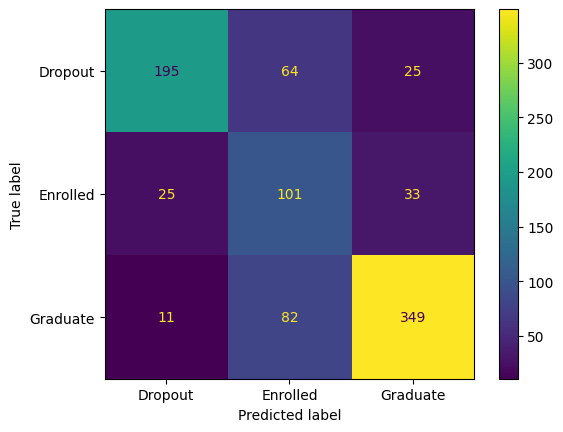

In [11]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt

# The model that won on validation is Logistic Regression with C=1
best = Pipeline([
    ("pre", pre),
    ("clf", LogisticRegression(C=1, max_iter=1000, class_weight="balanced"))
])

# Fit the best model on the training data and make predictions on the test set
best.fit(X_train, y_train)
y_pred = best.predict(X_test)

print(classification_report(y_test, y_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

**Which model you would trust for an early-warning system, which class it struggles with, and one risk of deploying it.**

I would trust Logistic Regression (C=1) for the early-warning system because it achieved the highest validation macro F1 score of 0.713 among the models tested. Based on the classification report, the model struggles most with the Enrolled category, which has the lowest recall of 0.635, meaning it has difficulty correctly identifying students in that group. One possible risk is that some students who are likely to drop out may not be identified early enough, preventing them from receiving the support they need.